## 运行说明

本 notebook 是该分析的用户入口：先检查并生成所需 `logs/`，再读取结果、完成分析并把图片写入同名 `figures/` 目录。

- 默认 `FORCE_RECOMPUTE = False`：已有日志直接复用，缺失日志才计算。
- 若需要从数据重新计算本 notebook 依赖的日志，将下一单元中的开关改为 `True`。
- 耗时较长的计算保留在同目录、同主题的 `.py` 中；短计算直接写在本 notebook 中。


In [1]:
from pathlib import Path
import subprocess

PROJECT_ROOT = Path('..').resolve()
SCRIPT_DIR = PROJECT_ROOT / 'scripts'
PYTHON = PROJECT_ROOT / 'venv/bin/python'
FORCE_RECOMPUTE = False

def run_long_task(script_name, sentinel, *arguments):
    sentinel = PROJECT_ROOT / sentinel
    if FORCE_RECOMPUTE or not sentinel.exists():
        command = [str(PYTHON), str(SCRIPT_DIR / script_name), *map(str, arguments)]
        print('运行：', ' '.join(command))
        subprocess.run(command, cwd=PROJECT_ROOT, check=True)
    else:
        print('复用：', sentinel.relative_to(PROJECT_ROOT))

run_long_task('261027空间事件传播.py', 'logs/spatial_bin_event_propagation/initial/summary.csv')
run_long_task('261027空间事件传播.py', 'logs/spatial_bin_event_propagation/seed_20261010/summary.csv', '--seed', '20261010', '--output-dir', 'logs/spatial_bin_event_propagation/seed_20261010')
run_long_task('261027空间事件传播.py', 'logs/spatial_bin_event_propagation/seed_20261011/summary.csv', '--seed', '20261011', '--output-dir', 'logs/spatial_bin_event_propagation/seed_20261011')
run_long_task('261027空间方程库.py', 'logs/spatial_pde_library/initial/model_summary.csv')
run_long_task('261027空间方程库.py', 'logs/spatial_pde_library/seed_20261010/model_summary.csv', '--event-arrays', 'logs/spatial_bin_event_propagation/seed_20261010/event_arrays.npz', '--output-dir', 'logs/spatial_pde_library/seed_20261010')
run_long_task('261027空间方程库.py', 'logs/spatial_pde_library/seed_20261011/model_summary.csv', '--event-arrays', 'logs/spatial_bin_event_propagation/seed_20261011/event_arrays.npz', '--output-dir', 'logs/spatial_pde_library/seed_20261011')


复用： logs/spatial_bin_event_propagation/initial/summary.csv
复用： logs/spatial_bin_event_propagation/seed_20261010/summary.csv
复用： logs/spatial_bin_event_propagation/seed_20261011/summary.csv
复用： logs/spatial_pde_library/initial/model_summary.csv
复用： logs/spatial_pde_library/seed_20261010/model_summary.csv
复用： logs/spatial_pde_library/seed_20261011/model_summary.csv


# Spatial equation library

Local bin-specific feedback is augmented with graph diffusion and shared first spatial derivatives. Three independent cell samples use identical episode splits.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from yumeow_plot import get_fig
ROOT = Path('..').resolve()
RUNS = ROOT / 'logs/spatial_pde_library'
OUT = ROOT / 'figures/261027空间方程库'
OUT.mkdir(parents=True, exist_ok=True)
names = ['initial', 'seed_20261010', 'seed_20261011']
summaries, coefficients = [], []
for run in names:
    s = pd.read_csv(RUNS / run / 'model_summary.csv'); s['run'] = run; summaries.append(s)
    c = pd.read_csv(RUNS / run / 'coefficients.csv'); c['run'] = run; coefficients.append(c)
summaries = pd.concat(summaries, ignore_index=True)
coefficients = pd.concat(coefficients, ignore_index=True)

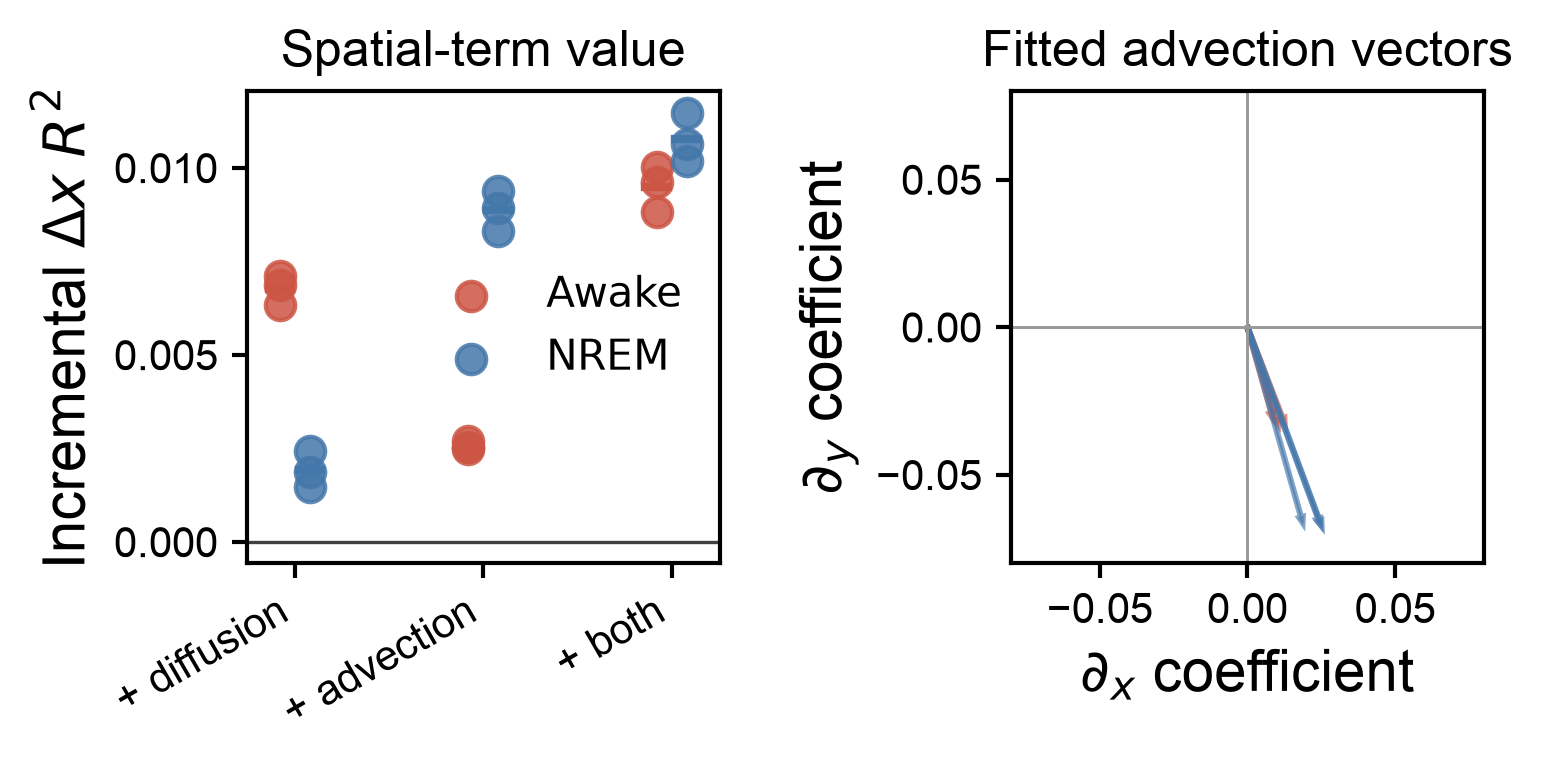

In [3]:
colors = {'Awake': '#cc5544', 'NREM': '#4477aa'}
models = ['local_diffusion', 'local_advection', 'local_advection_diffusion']
labels = ['+ diffusion', '+ advection', '+ both']
fig, axes = get_fig(RN=1, CN=2, AW=4, AH=4, LM=5, RM=5, TM=5, BM=5, VS=5, HS=5, fontsize=14, dpi=300, lw=1)
ax_loader = iter(axes)
ax = next(ax_loader)
for state, offset in [('Awake', -.08), ('NREM', .08)]:
    base = summaries[(summaries.state == state) & (summaries.model == 'local')].set_index('run').dx_r2_flat
    for index, model in enumerate(models):
        value = summaries[(summaries.state == state) & (summaries.model == model)].set_index('run').dx_r2_flat - base
        ax.scatter(np.full(len(value), index + offset), value, color=colors[state], s=50, alpha=.85, label=state if index == 0 else None)
        ax.plot([index + offset - .06, index + offset + .06], [value.mean(), value.mean()], color=colors[state], lw=2)
ax.axhline(0, color='0.25', lw=.8)
ax.set_xticks(range(3), labels, rotation=30, ha='right')
ax.set(ylabel=r'Incremental $\Delta x$ $R^2$', title='Spatial-term value')
ax.legend(frameon=False)
ax = next(ax_loader)
part = coefficients[(coefficients.model == 'local_advection_diffusion') & coefficients.term.isin(['gradient_x', 'gradient_y'])]
for state in ['Awake', 'NREM']:
    pivot = part[part.state == state].pivot(index='run', columns='term', values='coefficient_per_frame').loc[names]
    for _, row in pivot.iterrows():
        ax.arrow(0, 0, row.gradient_x, row.gradient_y, color=colors[state], alpha=.65, width=.0007, length_includes_head=True)
ax.axhline(0, color='0.6', lw=.7); ax.axvline(0, color='0.6', lw=.7)
ax.set(xlabel=r'$\partial_x$ coefficient', ylabel=r'$\partial_y$ coefficient', title='Fitted advection vectors', xlim=(-.08, .08), ylim=(-.08, .08))
ax.set_aspect('equal')
fig.savefig(OUT / 'spatial_pde_library.png', transparent=True)
fig.savefig(OUT / 'spatial_pde_library.svg', transparent=True)
fig.savefig(OUT / 'spatial_pde_library.pdf', transparent=True)
plt.show()

Across all three cell samples, diffusion plus advection improves held-out increment R² by about 0.009 in Awake and 0.011 in NREM beyond heterogeneous local feedback. NREM benefits more from advection than diffusion.

The fitted derivative vector is extremely stable: approximately (0.009–0.013, -0.034 to -0.032) per frame in Awake and (0.019–0.025, -0.068 to -0.067) in NREM. Its angle is roughly opposite the event lag-plane direction, as expected when the derivative coefficient points from later toward earlier locations in an advection equation. This is a coherent mathematical signature, while its biological versus acquisition origin remains unresolved.